# Customer Churn Prediction — Model Training

Pipeline: load data → clean → encode → split → train (Logistic Regression, Random Forest, XGBoost) → evaluate → save best model.

**Before running:** download the Telco Customer Churn dataset (Kaggle: "Telco Customer Churn IBM") and place the CSV at `data/telco_churn.csv`.

## 1. Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    RocCurveDisplay, ConfusionMatrixDisplay
)

sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)

## 2. Load Data

In [2]:
df = pd.read_csv('data/telco_churn.csv')
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## 3. Quick EDA
Just enough to sanity-check the data before modeling. (Deeper EDA with more visuals belongs in a separate notebook.)

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64


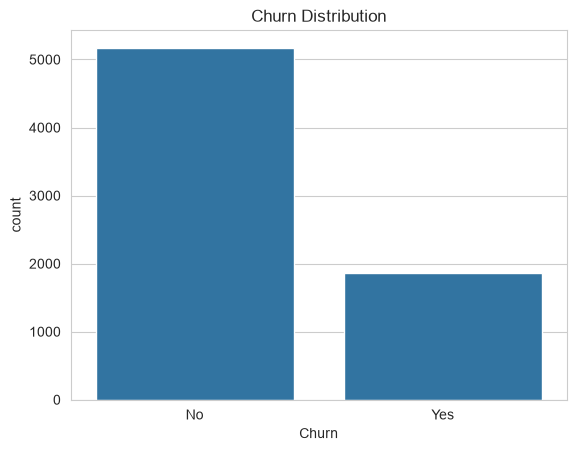

In [4]:
# Class balance — churn datasets are typically imbalanced
print(df['Churn'].value_counts())
print(df['Churn'].value_counts(normalize=True))

sns.countplot(data=df, x='Churn')
plt.title('Churn Distribution')
plt.show()

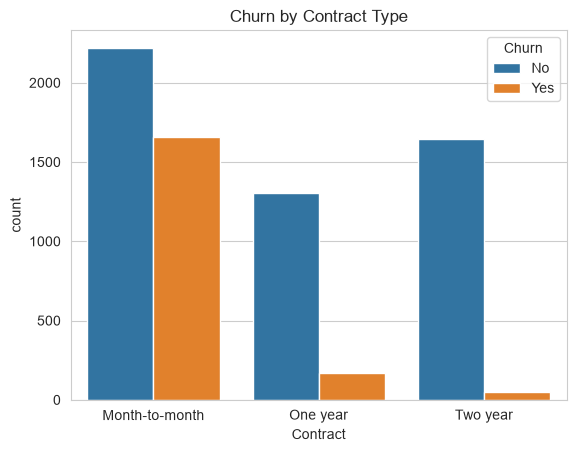

In [5]:
# Churn rate by contract type — usually the strongest predictor
sns.countplot(data=df, x='Contract', hue='Churn')
plt.title('Churn by Contract Type')
plt.show()

## 4. Data Cleaning

Known gotcha in this dataset: `TotalCharges` is stored as a string and has blank entries for customers with 0 tenure — these need to be handled before anything else.

In [6]:
# Drop customerID — it's an identifier, not a feature
df = df.drop(columns=['customerID'])

# Fix TotalCharges: coerce to numeric, blanks become NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print('Missing TotalCharges:', df['TotalCharges'].isna().sum())

# These are customers with 0 tenure -> TotalCharges should be 0
df['TotalCharges'] = df['TotalCharges'].fillna(0)

# Target to binary
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

Missing TotalCharges: 11


## 5. Encode Categorical Features

In [7]:
categorical_cols = df.select_dtypes(include='object').columns.tolist()
print('Categorical columns:', categorical_cols)

df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)
print(df_encoded.shape)
df_encoded.head()

Categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


/var/folders/kb/zzx1brld6t716sj_g2wdm19c0000gn/T/ipykernel_45158/2750314826.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include='object').columns.tolist()


(7043, 31)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,False,True,False,False,True,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,0,True,False,False,True,False,False,False,False,False,True,False,False,False,True,False,False,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,1,True,False,False,True,False,False,False,False,False,True,False,True,False,False,False,False,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,0,True,False,False,False,True,False,False,False,False,True,False,False,False,True,False,True,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,1,False,False,False,True,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,True,False


## 6. Train/Test Split + Scaling

In [8]:
X = df_encoded.drop(columns=['Churn'])
y = df_encoded['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
scaler = StandardScaler()
X_train[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test[numeric_cols] = scaler.transform(X_test[numeric_cols])

print('Train shape:', X_train.shape, ' Test shape:', X_test.shape)

Train shape: (5634, 30)  Test shape: (1409, 30)


## 7. Train Models

Using `class_weight='balanced'` / `scale_pos_weight` to handle the class imbalance instead of naive accuracy-chasing.

In [9]:
neg, pos = y_train.value_counts()[0], y_train.value_counts()[1]
scale_pos_weight = neg / pos

models = {
    'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000),
    'Random Forest': RandomForestClassifier(class_weight='balanced', n_estimators=200, random_state=42),
    'XGBoost': XGBClassifier(scale_pos_weight=scale_pos_weight, eval_metric='logloss', random_state=42)
}

results = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(y_test, proba)
    results[name] = {'model': model, 'preds': preds, 'proba': proba, 'auc': auc}
    print(f'--- {name} ---')
    print(f'ROC-AUC: {auc:.4f}')
    print(classification_report(y_test, preds))
    print()

--- Logistic Regression ---
ROC-AUC: 0.8417
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409


--- Random Forest ---
ROC-AUC: 0.8279
              precision    recall  f1-score   support

           0       0.87      0.82      0.84      1035
           1       0.57      0.65      0.60       374

    accuracy                           0.77      1409
   macro avg       0.72      0.73      0.72      1409
weighted avg       0.79      0.77      0.78      1409


--- XGBoost ---
ROC-AUC: 0.8185
              precision    recall  f1-score   support

           0       0.87      0.79      0.83      1035
           1       0.53      0.67      0.59       374

    accuracy                           0.76      1409
   macro avg

## 8. Compare Models

In [10]:
comparison = pd.DataFrame({
    name: {'ROC-AUC': res['auc']} for name, res in results.items()
}).T.sort_values('ROC-AUC', ascending=False)
comparison

,ROC-AUC
Logistic Regression,0.841732
Random Forest,0.827916
XGBoost,0.818497


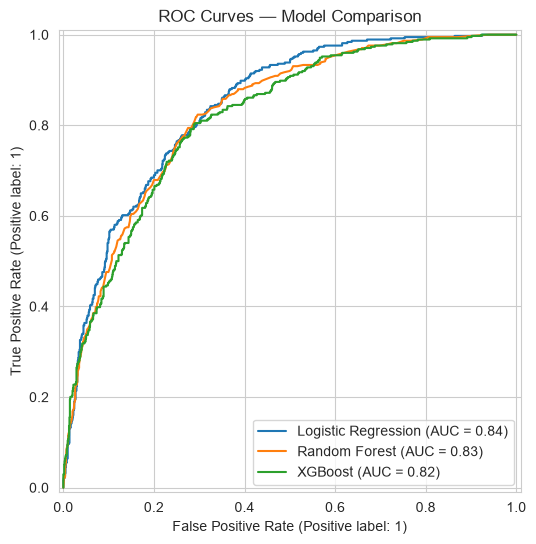

In [11]:
fig, ax = plt.subplots(figsize=(7, 6))
for name, res in results.items():
    RocCurveDisplay.from_predictions(y_test, res['proba'], name=name, ax=ax)
plt.title('ROC Curves — Model Comparison')
plt.show()

## 9. Confusion Matrix for Best Model

Best model: Logistic Regression


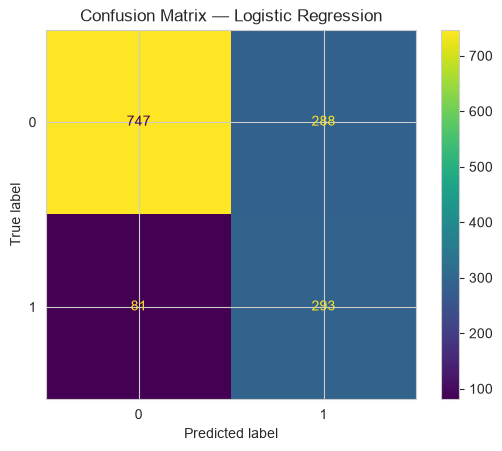

In [12]:
best_name = comparison.index[0]
best_model = results[best_name]['model']
print(f'Best model: {best_name}')

ConfusionMatrixDisplay.from_predictions(y_test, results[best_name]['preds'])
plt.title(f'Confusion Matrix — {best_name}')
plt.show()

## 10. Feature Importance (if tree-based)

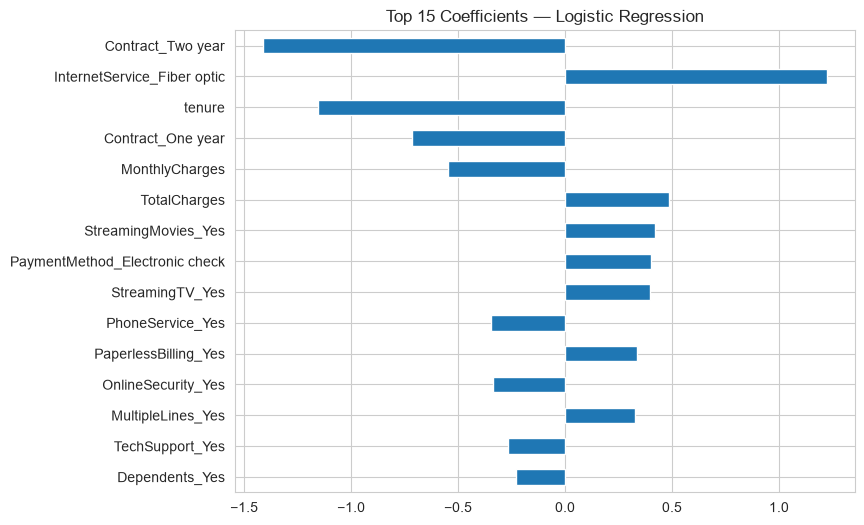

In [13]:
if hasattr(best_model, 'feature_importances_'):
    importances = pd.Series(best_model.feature_importances_, index=X.columns)
    importances.sort_values(ascending=False).head(15).plot(kind='barh', figsize=(8, 6))
    plt.title(f'Top 15 Feature Importances — {best_name}')
    plt.gca().invert_yaxis()
    plt.show()
else:
    coefs = pd.Series(best_model.coef_[0], index=X.columns)
    coefs.sort_values(key=abs, ascending=False).head(15).plot(kind='barh', figsize=(8, 6))
    plt.title(f'Top 15 Coefficients — {best_name}')
    plt.gca().invert_yaxis()
    plt.show()

## 11. Save Best Model + Scaler

In [14]:
joblib.dump(best_model, 'models/churn_model.pkl')
joblib.dump(scaler, 'models/scaler.pkl')
joblib.dump(list(X.columns), 'models/feature_columns.pkl')

print('Saved:')
print(' - models/churn_model.pkl')
print(' - models/scaler.pkl')
print(' - models/feature_columns.pkl')

Saved:
 - models/churn_model.pkl
 - models/scaler.pkl
 - models/feature_columns.pkl
